In [1]:
# If needed, uncomment:
# %pip install pandas numpy matplotlib seaborn scikit-learn statsmodels

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, classification_report,
    roc_auc_score
)
import statsmodels.api as sm

SEED = 603
TEST_SIZE = 0.30
np.random.seed(SEED)

print("Enrollment: 1603 | Dataset: German Credit | random_state:", SEED)

Enrollment: 1603 | Dataset: German Credit | random_state: 603


In [2]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

columns = [
    "checking_status", "duration", "credit_history", "purpose",
    "credit_amount", "savings", "employment_since", "installment_rate",
    "personal_status_sex", "other_debtors", "residence_since",
    "property", "age", "other_installment_plans", "housing",
    "existing_credits", "job", "dependents", "telephone",
    "foreign_worker", "credit_class"
]

df = pd.read_csv(DATA_URL, sep=r"\s+", header=None, names=columns)

# Assignment target: 1 = approve (good credit), 0 = reject (bad credit)
df["approval"] = (df["credit_class"] == 1).astype(int)
df.drop(columns=["credit_class"], inplace=True)

print("Dataset shape:", df.shape)
display(df.head())
print("\nTarget counts (0=reject, 1=approve):")
display(df["approval"].value_counts().rename_axis("approval").to_frame("count"))

Dataset shape: (1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,approval
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,0
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,0



Target counts (0=reject, 1=approve):


,count
approval,
1,700
0,300


In [3]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))

print("Missing values:")
display(df.isna().sum().to_frame("missing_count"))

numeric_cols = df.drop(columns="approval").select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.drop(columns="approval").select_dtypes(exclude=np.number).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

outlier_summary = []
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_summary.append([col, int(((df[col] < low) | (df[col] > high)).sum())])

display(pd.DataFrame(outlier_summary, columns=["numeric_feature", "IQR_outlier_count"]))

Data types:


,dtype
checking_status,object
duration,int64
credit_history,object
purpose,object
credit_amount,int64
savings,object
employment_since,object
installment_rate,int64
personal_status_sex,object
other_debtors,object


Missing values:


,missing_count
checking_status,0
duration,0
credit_history,0
purpose,0
credit_amount,0
savings,0
employment_since,0
installment_rate,0
personal_status_sex,0
other_debtors,0


Numeric columns: ['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'dependents']
Categorical columns: ['checking_status', 'credit_history', 'purpose', 'savings', 'employment_since', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']


,numeric_feature,IQR_outlier_count
0,duration,70
1,credit_amount,72
2,installment_rate,0
3,residence_since,0
4,age,23
5,existing_credits,6
6,dependents,155


In [4]:
X = df.drop(columns="approval").copy()
y = df["approval"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)

# Learn 1st and 99th percentile caps from training data only.
lower_caps = X_train[numeric_cols].quantile(0.01)
upper_caps = X_train[numeric_cols].quantile(0.99)

def cap_numeric(frame):
    frame = frame.copy()
    for col in numeric_cols:
        frame[col] = frame[col].clip(lower=lower_caps[col], upper=upper_caps[col])
    return frame

X_train_cap = cap_numeric(X_train)
X_test_cap = cap_numeric(X_test)

try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # compatibility with older scikit-learn versions
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot)
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
], remainder="drop")

X_train_ready = preprocessor.fit_transform(X_train_cap)
X_test_ready = preprocessor.transform(X_test_cap)

feature_names = preprocessor.get_feature_names_out()
X_train_ready = pd.DataFrame(X_train_ready, columns=feature_names, index=X_train.index)
X_test_ready = pd.DataFrame(X_test_ready, columns=feature_names, index=X_test.index)

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Processed training shape:", X_train_ready.shape)
print("Preprocessing summary:")
print("- Missing numeric values: median imputation")
print("- Missing categorical values: most-frequent imputation")
print("- Categorical encoding: one-hot encoding")
print("- Numeric scaling: standard scaling")
print("- Outliers: numeric values capped at training 1st/99th percentiles")

Training rows: 700 | Test rows: 300
Processed training shape: (700, 61)
Preprocessing summary:
- Missing numeric values: median imputation
- Missing categorical values: most-frequent imputation
- Categorical encoding: one-hot encoding
- Numeric scaling: standard scaling
- Outliers: numeric values capped at training 1st/99th percentiles


In [5]:
model_a = LinearRegression()
model_a.fit(X_train_ready, y_train)

pred_a = model_a.predict(X_test_ready)
threshold_a = float(np.median(pred_a))
class_a = (pred_a >= threshold_a).astype(int)

print("Model A median predicted value (threshold):", round(threshold_a, 4))
print("Model A test R-squared:", round(model_a.score(X_test_ready, y_test), 4))

Model A median predicted value (threshold): 0.7069
Model A test R-squared: 0.1746


In [6]:
model_b = LogisticRegression(max_iter=3000, random_state=SEED)
model_b.fit(X_train_ready, y_train)

prob_b = model_b.predict_proba(X_test_ready)[:, 1]
class_b = (prob_b >= 0.5).astype(int)

print("Model B test accuracy:", round(accuracy_score(y_test, class_b), 4))
print("Model B ROC-AUC:", round(roc_auc_score(y_test, prob_b), 4))
print(classification_report(y_test, class_b, target_names=["Reject (0)", "Approve (1)"]))

Model B test accuracy: 0.7567
Model B ROC-AUC: 0.7766
              precision    recall  f1-score   support

  Reject (0)       0.61      0.52      0.56        90
 Approve (1)       0.81      0.86      0.83       210

    accuracy                           0.76       300
   macro avg       0.71      0.69      0.70       300
weighted avg       0.75      0.76      0.75       300



In [8]:
comparison_matrix = confusion_matrix(class_a, class_b, labels=[0, 1])
mismatch = (class_a != class_b)
mismatch_count = int(mismatch.sum())
mismatch_pct = 100 * mismatch.mean()

print("Rows = Model A class; columns = Model B class")
display(pd.DataFrame(
    comparison_matrix,
    index=["Model A: 0", "Model A: 1"],
    columns=["Model B: 0", "Model B: 1"]
))

print(f"Mismatched cases: {mismatch_count} / {len(y_test)} ({mismatch_pct:.2f}%)")
print("Model A median threshold:", round(threshold_a, 4), "| Model B threshold: 0.5000")

Rows = Model A class; columns = Model B class


,Model B: 0,Model B: 1
Model A: 0,77,73
Model A: 1,0,150


Mismatched cases: 73 / 300 (24.33%)
Model A median threshold: 0.7069 | Model B threshold: 0.5000


In [9]:
def fit_glm_logit(X_frame, y_series):
    X_sm = sm.add_constant(X_frame.astype(float), has_constant="add")
    model = sm.GLM(y_series.astype(float), X_sm, family=sm.families.Binomial())
    return model.fit(maxiter=200)

def safe_ratio(a, b):
    if pd.isna(a) or pd.isna(b) or b == 0:
        return np.nan
    return a / b

# Full-data transformed matrix for subgroup and omitted-variable analyses.
X_all_cap = cap_numeric(X)
X_all_ready = pd.DataFrame(
    preprocessor.transform(X_all_cap),
    columns=feature_names,
    index=X.index
)

full_glm = fit_glm_logit(X_all_ready, y)
print(full_glm.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:               approval   No. Observations:                 1000
Model:                            GLM   Df Residuals:                      951
Model Family:                Binomial   Df Model:                           48
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -447.77
Date:                Thu, 26 Nov 2026   Deviance:                       895.54
Time:                        06:11:38   Pearson chi2:                     958.
No. Iterations:                     9   Pseudo R-squ. (CS):             0.2783
Covariance Type:            nonrobust                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
const 

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


In [10]:
# German Statlog personal_status_sex codes:
# A91/A93/A94 = male; A92/A95 = female
sex_code = X["personal_status_sex"].astype(str)
gender_group = pd.Series(index=X.index, dtype="object")
gender_group[sex_code.isin(["A91", "A93", "A94"])] = "Male"
gender_group[sex_code.isin(["A92", "A95"])] = "Female"

print("Gender group counts:")
display(gender_group.value_counts(dropna=False).to_frame("count"))

male_idx = gender_group[gender_group == "Male"].index
female_idx = gender_group[gender_group == "Female"].index

subgroup_models = {
    "Full dataset": full_glm,
    "Male": fit_glm_logit(X_all_ready.loc[male_idx], y.loc[male_idx]),
    "Female": fit_glm_logit(X_all_ready.loc[female_idx], y.loc[female_idx])
}

# Numeric feature columns after preprocessing
numeric_feature_names = [name for name in feature_names if name.startswith("num__")]
simpson_rows = []
for feat in numeric_feature_names:
    vals = {group: model.params.get(feat, np.nan)
            for group, model in subgroup_models.items()}
    simpson_rows.append({"feature": feat, **vals})

simpson_table = pd.DataFrame(simpson_rows)
simpson_table["male_female_sign_reversal"] = (
    np.sign(simpson_table["Male"]) != np.sign(simpson_table["Female"])
)
simpson_table["male_female_abs_difference"] = (
    simpson_table["Male"] - simpson_table["Female"]
).abs()
display(simpson_table.sort_values("male_female_abs_difference", ascending=False))

print("Coefficient confidence intervals for the strongest male/female difference:")
chosen_simpson_feature = simpson_table.sort_values(
    "male_female_abs_difference", ascending=False
).iloc[0]["feature"]
for group, fitted in subgroup_models.items():
    print("\n", group, "|", chosen_simpson_feature)
    print("Coefficient:", fitted.params.get(chosen_simpson_feature, np.nan))
    print("95% CI:", fitted.conf_int().loc[chosen_simpson_feature].tolist())

Gender group counts:


,count
Male,690
Female,310


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


,feature,Full dataset,Male,Female,male_female_sign_reversal,male_female_abs_difference
4,num__age,0.162050,-0.038740,0.758009,True,0.796748
6,num__dependents,-0.095522,-0.037660,-0.695586,False,0.657926
2,num__installment_rate,-0.368104,-0.292801,-0.767562,False,0.474761
5,num__existing_credits,-0.169752,-0.131352,-0.474584,False,0.343232
0,num__duration,-0.336568,-0.320437,-0.600672,False,0.280235
3,num__residence_since,-0.007204,0.081845,-0.154454,True,0.236299
1,num__credit_amount,-0.349371,-0.314676,-0.283147,False,0.031530


Coefficient confidence intervals for the strongest male/female difference:

 Full dataset | num__age
Coefficient: 0.16205025006126772
95% CI: [-0.04176804793989314, 0.3658685480624286]

 Male | num__age
Coefficient: -0.038739518500791346
95% CI: [-0.2986238501415213, 0.22114481313993864]

 Female | num__age
Coefficient: 0.758008558117476
95% CI: [0.2888984188901867, 1.2271186973447654]


In [11]:
omitted_variable = "credit_history"
reduced_columns = [c for c in X_all_ready.columns
                   if not c.startswith("cat__credit_history_")]
reduced_glm = fit_glm_logit(X_all_ready[reduced_columns], y)

# Select at least four numeric predictors, or all available if fewer.
predictors_to_compare = numeric_feature_names[:]
ovb_rows = []
for feat in predictors_to_compare:
    before = full_glm.params.get(feat, np.nan)
    after = reduced_glm.params.get(feat, np.nan)
    pct_change = np.nan
    if pd.notna(before) and abs(before) > 1e-10:
        pct_change = ((after - before) / abs(before)) * 100
    ovb_rows.append({
        "predictor": feat,
        "full_model_coefficient": before,
        "reduced_model_coefficient": after,
        "absolute_shift": abs(after - before),
        "percentage_change": pct_change
    })

ovb_table = pd.DataFrame(ovb_rows)
display(ovb_table.sort_values("absolute_shift", ascending=False))
print("Deliberately omitted variable:", omitted_variable)
print("Largest absolute coefficient shift:")
display(ovb_table.loc[ovb_table["absolute_shift"].idxmax()].to_frame("value"))

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


,predictor,full_model_coefficient,reduced_model_coefficient,absolute_shift,percentage_change
5,num__existing_credits,-0.169752,0.036885,0.206637,121.728753
6,num__dependents,-0.095522,-0.119145,0.023623,-24.730332
2,num__installment_rate,-0.368104,-0.353379,0.014724,4.000055
3,num__residence_since,-0.007204,0.005572,0.012776,177.357738
4,num__age,0.162050,0.174328,0.012278,7.576620
0,num__duration,-0.336568,-0.334552,0.002016,0.598904
1,num__credit_amount,-0.349371,-0.351179,0.001807,-0.517278


Deliberately omitted variable: credit_history
Largest absolute coefficient shift:


,value
predictor,num__existing_credits
full_model_coefficient,-0.169752
reduced_model_coefficient,0.036885
absolute_shift,0.206637
percentage_change,121.728753


In [12]:
adversarial = X_test.copy()
adversarial["actual_approval"] = y_test
adversarial["predicted_probability"] = prob_b
adversarial["predicted_class"] = class_b

false_positive_confident = (
    (adversarial["predicted_probability"] >= 0.75) &
    (adversarial["actual_approval"] == 0)
)
false_negative_confident = (
    (adversarial["predicted_probability"] <= 0.25) &
    (adversarial["actual_approval"] == 1)
)
wrong_mask = false_positive_confident | false_negative_confident
wrong_all = adversarial.loc[wrong_mask].copy()

wrong_count = len(wrong_all)
wrong_pct = 100 * wrong_count / len(X_test)
adversarial_50 = wrong_all.sample(
    n=min(50, wrong_count), random_state=SEED
) if wrong_count else wrong_all

print(f"High-confidence wrong predictions: {wrong_count} ({wrong_pct:.2f}% of test set)")
print("Rows selected for adversarial subset:", len(adversarial_50))
display(adversarial_50.head(10))

# Compare age and gender distributions with the full test set.
test_gender = gender_group.loc[X_test.index]
subset_gender = gender_group.loc[adversarial_50.index] if len(adversarial_50) else pd.Series(dtype="object")

print("\nAge distribution – full test set:")
display(X_test["age"].describe())
print("\nAge distribution – adversarial subset:")
display(adversarial_50["age"].describe() if len(adversarial_50) else "No adversarial cases found.")

print("\nGender proportions – full test set:")
display(test_gender.value_counts(normalize=True).rename("proportion"))
print("\nGender proportions – adversarial subset:")
display(subset_gender.value_counts(normalize=True).rename("proportion"))

# Identify common categorical/numeric characteristics in the subset.
if len(adversarial_50):
    print("\nMost common categorical values in adversarial subset:")
    for col in categorical_cols:
        print("\n", col)
        display(adversarial_50[col].value_counts(normalize=True).head(5).rename("proportion"))
    print("\nNumeric summary of adversarial subset:")
    display(adversarial_50[numeric_cols].describe())

High-confidence wrong predictions: 23 (7.67% of test set)
Rows selected for adversarial subset: 23


,checking_status,duration,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,...,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,actual_approval,predicted_probability,predicted_class
268,A11,14,A32,A40,8978,A61,A75,1,A91,A101,...,A143,A152,1,A174,1,A192,A202,0,0.846586,1
402,A14,24,A33,A49,8648,A61,A72,2,A93,A101,...,A141,A152,2,A173,1,A192,A201,0,0.876869,1
650,A11,48,A32,A46,7476,A61,A74,4,A93,A101,...,A143,A153,1,A174,1,A192,A201,1,0.131816,0
952,A12,24,A32,A41,4113,A63,A72,3,A92,A101,...,A143,A151,1,A173,1,A191,A201,0,0.848948,1
949,A14,24,A32,A43,3621,A62,A75,2,A93,A101,...,A143,A152,2,A173,1,A191,A201,0,0.932797,1
213,A13,30,A33,A49,1908,A61,A75,4,A93,A101,...,A143,A152,1,A174,1,A192,A201,0,0.925559,1
137,A12,12,A32,A43,766,A63,A73,4,A93,A101,...,A143,A152,1,A172,1,A191,A201,0,0.944129,1
14,A11,15,A32,A40,1403,A61,A73,2,A92,A101,...,A143,A151,1,A173,1,A191,A201,1,0.233358,0
559,A12,18,A34,A42,1928,A61,A72,2,A93,A101,...,A143,A152,2,A172,1,A191,A201,0,0.868076,1
815,A12,36,A33,A40,7432,A61,A73,2,A92,A101,...,A143,A151,1,A173,1,A191,A201,1,0.192003,0



Age distribution – full test set:


,age
count,300.000000
mean,35.286667
std,11.573431
min,20.000000
25%,26.750000
50%,32.000000
75%,41.000000
max,75.000000



Age distribution – adversarial subset:


,age
count,23.000000
mean,37.478261
std,13.540745
min,23.000000
25%,28.000000
50%,31.000000
75%,47.500000
max,66.000000


... (28 outputs left out)


 foreign_worker


,proportion
foreign_worker,
A201,0.913043
A202,0.086957



Numeric summary of adversarial subset:


,duration,credit_amount,installment_rate,residence_since,age,existing_credits,dependents
count,23.000000,23.000000,23.000000,23.000000,23.000000,23.000000,23.000000
mean,21.304348,4392.869565,2.695652,2.652174,37.478261,1.478261,1.086957
std,12.005434,3809.956422,1.222322,1.112274,13.540745,0.665348,0.288104
min,6.000000,609.000000,1.000000,1.000000,23.000000,1.000000,1.000000
25%,12.000000,1479.000000,2.000000,2.000000,28.000000,1.000000,1.000000
50%,21.000000,2580.000000,3.000000,2.000000,31.000000,1.000000,1.000000
75%,25.500000,7454.000000,4.000000,4.000000,47.500000,2.000000,1.000000
max,48.000000,14555.000000,4.000000,4.000000,66.000000,3.000000,2.000000


In [13]:
fairness_data = pd.DataFrame({
    "y": y_test.to_numpy(),
    "prob": prob_b,
    "gender": gender_group.loc[X_test.index].to_numpy()
}, index=X_test.index)

fairness_data = fairness_data[fairness_data["gender"].isin(["Male", "Female"])].copy()
thresholds = np.round(np.arange(0.05, 0.951, 0.10), 2)

def group_rates(frame, group, threshold):
    part = frame[frame["gender"] == group]
    pred = (part["prob"] >= threshold).astype(int)
    actual = part["y"].astype(int)
    selection_rate = pred.mean() if len(part) else np.nan
    tp = ((pred == 1) & (actual == 1)).sum()
    fn = ((pred == 0) & (actual == 1)).sum()
    fp = ((pred == 1) & (actual == 0)).sum()
    tn = ((pred == 0) & (actual == 0)).sum()
    tpr = tp / (tp + fn) if (tp + fn) else np.nan
    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    return selection_rate, tpr, fpr, precision

fairness_rows = []
for t in thresholds:
    male = group_rates(fairness_data, "Male", t)
    female = group_rates(fairness_data, "Female", t)
    dp = safe_ratio(male[0], female[0])
    tpr_ratio = safe_ratio(male[1], female[1])
    fpr_ratio = safe_ratio(male[2], female[2])
    eo = np.nanmin([tpr_ratio, fpr_ratio]) if not (pd.isna(tpr_ratio) and pd.isna(fpr_ratio)) else np.nan
    pp = safe_ratio(male[3], female[3])
    fairness_rows.append({
        "threshold": t, "DP_ratio": dp, "EO_ratio": eo, "PP_ratio": pp,
        "Male_selection_rate": male[0], "Female_selection_rate": female[0],
        "Male_TPR": male[1], "Female_TPR": female[1],
        "Male_FPR": male[2], "Female_FPR": female[2],
        "Male_precision": male[3], "Female_precision": female[3]
    })

fairness_table = pd.DataFrame(fairness_rows)
display(fairness_table.round(4))

,threshold,DP_ratio,EO_ratio,PP_ratio,Male_selection_rate,Female_selection_rate,Male_TPR,Female_TPR,Male_FPR,Female_FPR,Male_precision,Female_precision
0,0.05,0.9952,0.9825,1.1375,0.9952,1.0000,1.0000,1.0000,0.9825,1.0000,0.7295,0.6413
1,0.15,0.9878,0.9525,1.1384,0.9663,0.9783,0.9934,1.0000,0.8947,0.9394,0.7463,0.6556
2,0.25,1.0498,1.0078,1.1285,0.9471,0.9022,0.9934,0.9492,0.8246,0.8182,0.7614,0.6747
3,0.35,1.1088,1.0711,1.0989,0.8798,0.7935,0.9669,0.8983,0.6491,0.6061,0.7978,0.7260
4,0.45,1.1058,0.9649,1.1200,0.8173,0.7391,0.9272,0.8475,0.5263,0.5455,0.8235,0.7353
5,0.55,1.2084,0.9511,1.1329,0.7356,0.6087,0.8609,0.7119,0.4035,0.4242,0.8497,0.7500
6,0.65,1.2808,1.1579,1.0814,0.6683,0.5217,0.7881,0.6441,0.3509,0.3030,0.8561,0.7917
7,0.75,1.5816,1.4513,1.0387,0.5673,0.3587,0.6887,0.4746,0.2456,0.1515,0.8814,0.8485
8,0.85,1.7692,1.5096,0.9659,0.4615,0.2609,0.5629,0.3729,0.1930,0.0606,0.8854,0.9167
9,0.95,2.7276,0.5789,1.1676,0.1779,0.0652,0.2384,0.0847,0.0175,0.0303,0.9730,0.8333


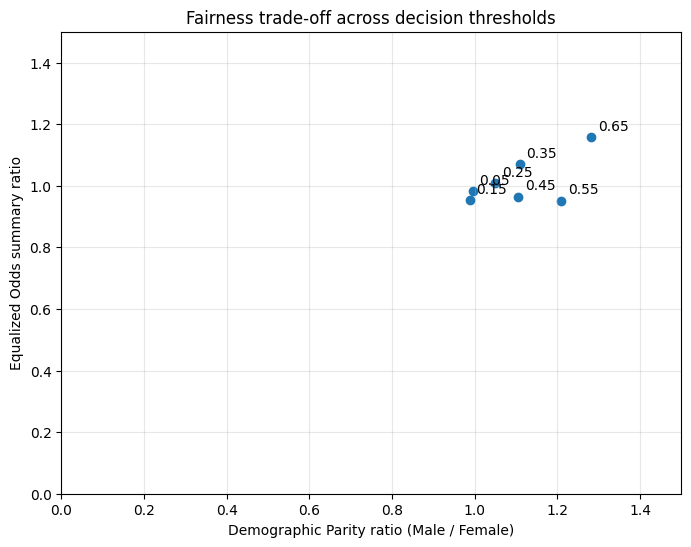

Ideal parity/equalized-odds ratio = 1.0.
Closest DP threshold:


,threshold,DP_ratio,EO_ratio,PP_ratio,Male_selection_rate,Female_selection_rate,Male_TPR,Female_TPR,Male_FPR,Female_FPR,Male_precision,Female_precision
0,0.05,0.995192,0.982456,1.137476,0.995192,1.0,1.0,1.0,0.982456,1.0,0.729469,0.641304


Closest EO threshold:


,threshold,DP_ratio,EO_ratio,PP_ratio,Male_selection_rate,Female_selection_rate,Male_TPR,Female_TPR,Male_FPR,Female_FPR,Male_precision,Female_precision
2,0.25,1.049815,1.007797,1.128535,0.947115,0.902174,0.993377,0.949153,0.824561,0.818182,0.761421,0.674699


In [14]:
plt.figure(figsize=(8, 6))
valid = fairness_table.dropna(subset=["DP_ratio", "EO_ratio"])
plt.scatter(valid["DP_ratio"], valid["EO_ratio"])
for _, row in valid.iterrows():
    plt.annotate(f'{row["threshold"]:.2f}',
                 (row["DP_ratio"], row["EO_ratio"]),
                 xytext=(5, 5), textcoords="offset points")
plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity ratio (Male / Female)")
plt.ylabel("Equalized Odds summary ratio")
plt.title("Fairness trade-off across decision thresholds")
plt.grid(True, alpha=0.3)
plt.show()

print("Ideal parity/equalized-odds ratio = 1.0.")
print("Closest DP threshold:")
display(fairness_table.iloc[(fairness_table["DP_ratio"] - 1).abs().argsort()[:1]])
print("Closest EO threshold:")
display(fairness_table.iloc[(fairness_table["EO_ratio"] - 1).abs().argsort()[:1]])

In [15]:
results_dir = "cset485_results"
import os
os.makedirs(results_dir, exist_ok=True)

pd.DataFrame({
    "actual": y_test,
    "model_a_prediction": pred_a,
    "model_a_class": class_a,
    "model_b_probability": prob_b,
    "model_b_class": class_b
}, index=y_test.index).to_csv(f"{results_dir}/test_predictions.csv")

simpson_table.to_csv(f"{results_dir}/simpson_subgroup_coefficients.csv", index=False)
ovb_table.to_csv(f"{results_dir}/omitted_variable_bias.csv", index=False)
adversarial_50.to_csv(f"{results_dir}/adversarial_subset.csv", index=True)
fairness_table.to_csv(f"{results_dir}/fairness_metrics_by_threshold.csv", index=False)

print("Saved result files in:", results_dir)
print("Confusion matrix (Model A vs Model B):")
display(pd.DataFrame(comparison_matrix))
print("Mismatch count:", mismatch_count, "| Mismatch percentage:", round(mismatch_pct, 2))
print("Model B accuracy:", round(accuracy_score(y_test, class_b), 4))
print("Model B ROC-AUC:", round(roc_auc_score(y_test, prob_b), 4))

Saved result files in: cset485_results
Confusion matrix (Model A vs Model B):


,0,1
0,77,73
1,0,150


Mismatch count: 73 | Mismatch percentage: 24.33
Model B accuracy: 0.7567
Model B ROC-AUC: 0.7766
